In [ ]:
from google.colab import drive
drive.mount('/content/drive')


ValueError: mount failed

In [ ]:
import pandas as pd

DATA_PATH = "/content/drive/MyDrive/phishing_research_new/datasets/phishing_url_integrated.csv"

df = pd.read_csv(DATA_PATH)

df.head()


,url,label
0,www.voting-yahoo.com,0
1,www.zvon.org/xxl/wsdl1.1/output/index.html,0
2,tecportais.com/file-security-update-infonfmati...,0
3,bima.astro.umd.edu/nemo/linuxastro/,0
4,huarui-tec.com/js/?us.battle.net/login/en/?ref...,0


In [ ]:
# pastikan tipe data
df['url'] = df['url'].astype(str)

# lowercase (konsisten)
df['url'] = df['url'].str.lower()

# drop missing
df.dropna(inplace=True)

print("Total samples:", len(df))


Total samples: 565517


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 565517 entries, 0 to 565516
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   url     565517 non-null  object
 1   label   565517 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 8.6+ MB


In [ ]:
#menampilkan jumlah data kosong untuk masing-masing atribut
df.isnull().sum()

,0
url,0
label,0


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 200
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(
    char_level=True,
    lower=True,
    oov_token=OOV_TOKEN
)

tokenizer.fit_on_texts(df['url'])

sequences = tokenizer.texts_to_sequences(df['url'])


In [ ]:
X = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

y = df['label'].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (565517, 200)
y shape: (565517,)


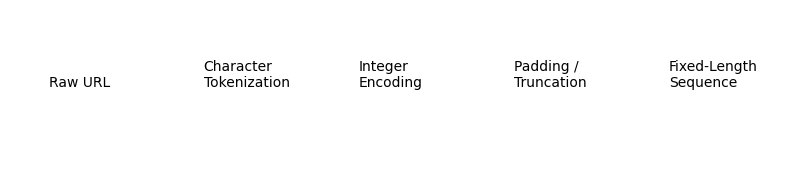

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 2))
ax.text(0.05, 0.5, "Raw URL", fontsize=10)
ax.text(0.25, 0.5, "Character\nTokenization", fontsize=10)
ax.text(0.45, 0.5, "Integer\nEncoding", fontsize=10)
ax.text(0.65, 0.5, "Padding /\nTruncation", fontsize=10)
ax.text(0.85, 0.5, "Fixed-Length\nSequence", fontsize=10)

ax.axis('off')
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)


Train: (452413, 200)
Test : (113104, 200)


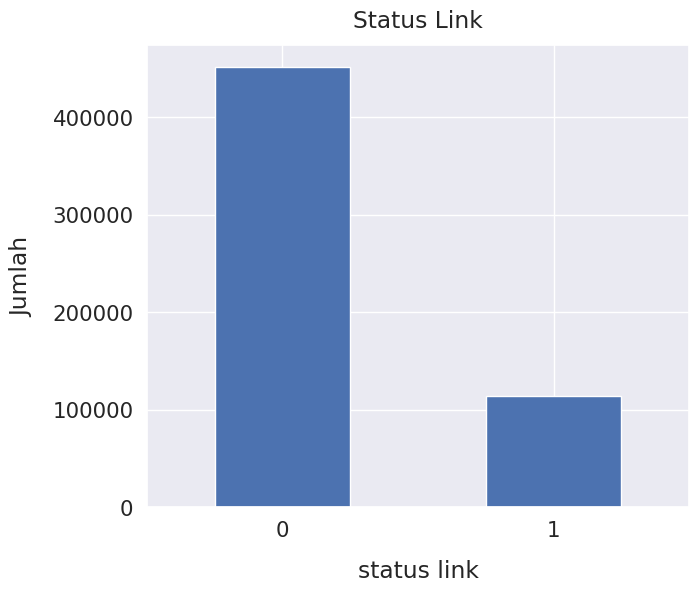

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(font_scale=1.4)
df['label'].value_counts().plot(kind='bar', figsize=(7, 6), rot=0)
plt.xlabel("status link", labelpad=14)
plt.ylabel("Jumlah", labelpad=14)
plt.title("Status Link", y=1.02);

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(weights))
class_weights

{0: np.float64(0.6264528886070271), 1: np.float64(2.477020871202996)}

CNN (Feature Extractor)

In [ ]:
# =========================
# CNN PARAMETERS
# =========================
MAX_LEN = X_train.shape[1]
VOCAB_SIZE = len(tokenizer.word_index) + 1

EMBEDDING_DIM = 32
NUM_FILTERS = 128
KERNEL_SIZE = 5
FEATURE_DIM = 128   # dimensi feature vector output CNN

print("Vocab size:", VOCAB_SIZE)
print("Max length:", MAX_LEN)


Vocab size: 159
Max length: 200


In [ ]:
from tensorflow.keras.layers import Input, Embedding, Conv1D, GlobalMaxPooling1D, Dense
from tensorflow.keras.models import Model

def build_cnn_feature_extractor():
    inputs = Input(shape=(MAX_LEN,), name="input_url")

    x = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        input_length=MAX_LEN,
        name="embedding"
    )(inputs)

    x = Conv1D(
        filters=NUM_FILTERS,
        kernel_size=KERNEL_SIZE,
        activation='relu',
        name="conv1d"
    )(x)

    x = GlobalMaxPooling1D(name="global_max_pooling")(x)

    features = Dense(
        FEATURE_DIM,
        activation='relu',
        name="feature_vector"
    )(x)

    model = Model(inputs=inputs, outputs=features, name="CNN_Feature_Extractor")

    return model


In [ ]:
def build_cnn_with_classifier(feature_extractor):
    x = feature_extractor.output
    output = Dense(1, activation='sigmoid', name="classifier")(x)

    model = Model(
        inputs=feature_extractor.input,
        outputs=output,
        name="CNN_Temporary_Classifier"
    )

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


In [ ]:
cnn_feature_extractor = build_cnn_feature_extractor()
cnn_model = build_cnn_with_classifier(cnn_feature_extractor)

cnn_model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "CNN_Temporary_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_url (InputLayer)          │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 32)        │         5,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 196, 128)       │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling              │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_vector (Dense)          │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,337 (165.38 KB)

 Trainable params: 42,337 (165.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = cnn_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=256,
    verbose=1
)


Epoch 1/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.9645 - loss: 0.0943 - val_accuracy: 0.9896 - val_loss: 0.0294
Epoch 2/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9905 - loss: 0.0286 - val_accuracy: 0.9916 - val_loss: 0.0239
Epoch 3/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9927 - loss: 0.0224 - val_accuracy: 0.9930 - val_loss: 0.0210
Epoch 4/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9939 - loss: 0.0189 - val_accuracy: 0.9931 - val_loss: 0.0216
Epoch 5/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9942 - loss: 0.0175 - val_accuracy: 0.9936 - val_loss: 0.0195


In [ ]:
for layer in cnn_feature_extractor.layers:
    layer.trainable = False

print("CNN feature extractor frozen.")


CNN feature extractor frozen.


In [ ]:
X_train_cnn = cnn_feature_extractor.predict(X_train, batch_size=512)
X_test_cnn  = cnn_feature_extractor.predict(X_test, batch_size=512)

print("Train feature shape:", X_train_cnn.shape)
print("Test feature shape :", X_test_cnn.shape)


884/884 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Train feature shape: (452413, 128)
Test feature shape : (113104, 128)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight="balanced",  # penting untuk imbalance
    random_state=42,
    n_jobs=-1
)

rf_clf.fit(X_train_cnn, y_train)


RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred_rf = rf_clf.predict(X_test_cnn)
y_prob_rf = rf_clf.predict_proba(X_test_cnn)[:, 1]

rf_results = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1-score": f1_score(y_test, y_pred_rf),
    "AUC-ROC": roc_auc_score(y_test, y_prob_rf)
}

rf_results


{'Accuracy': 0.9955881312774084,
 'Precision': 0.9916776750330251,
 'Recall': 0.9864219701283343,
 'F1-score': 0.989042840517336,
 'AUC-ROC': np.float64(0.9990709828918575)}

In [ ]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

xgb_clf.fit(X_train_cnn, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb = xgb_clf.predict(X_test_cnn)
y_prob_xgb = xgb_clf.predict_proba(X_test_cnn)[:, 1]

xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1-score": f1_score(y_test, y_pred_xgb),
    "AUC-ROC": roc_auc_score(y_test, y_prob_xgb)
}

xgb_results


{'Accuracy': 0.9945006365822606,
 'Precision': 0.9821544874299857,
 'Recall': 0.9907581796679953,
 'F1-score': 0.9864375735903362,
 'AUC-ROC': np.float64(0.999464476343366)}

TRANSFORMER (Feature Extractor)

In [ ]:
# =========================
# TRANSFORMER PARAMETERS
# =========================
NUM_HEADS = 4
FF_DIM = 128          # feed-forward dim
TRANSFORMER_LAYERS = 1
DROPOUT_RATE = 0.1


In [ ]:
from tensorflow.keras.layers import Layer
import tensorflow as tf

class PositionalEncoding(Layer):
    def __init__(self, max_len, embed_dim):
        super().__init__()
        self.pos_emb = Embedding(input_dim=max_len, output_dim=embed_dim)

    def call(self, x):
        positions = tf.range(start=0, limit=tf.shape(x)[1], delta=1)
        positions = self.pos_emb(positions)
        return x + positions


In [ ]:
from tensorflow.keras.layers import MultiHeadAttention, Dense, Dropout, LayerNormalization

def transformer_encoder(inputs):
    # Self-attention
    attention = MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=EMBEDDING_DIM
    )(inputs, inputs)

    attention = Dropout(DROPOUT_RATE)(attention)
    attention = LayerNormalization(epsilon=1e-6)(inputs + attention)

    # Feed-forward
    ffn = Dense(FF_DIM, activation="relu")(attention)
    ffn = Dense(EMBEDDING_DIM)(ffn)
    ffn = Dropout(DROPOUT_RATE)(ffn)

    return LayerNormalization(epsilon=1e-6)(attention + ffn)


In [ ]:
from tensorflow.keras.layers import GlobalAveragePooling1D

def build_transformer_feature_extractor():
    inputs = Input(shape=(MAX_LEN,), name="input_url")

    x = Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        input_length=MAX_LEN,
        name="embedding"
    )(inputs)

    x = PositionalEncoding(MAX_LEN, EMBEDDING_DIM)(x)

    for _ in range(TRANSFORMER_LAYERS):
        x = transformer_encoder(x)

    x = GlobalAveragePooling1D(name="global_avg_pooling")(x)

    features = Dense(
        FEATURE_DIM,
        activation="relu",
        name="feature_vector"
    )(x)

    model = Model(inputs=inputs, outputs=features, name="Transformer_Feature_Extractor")
    return model


In [ ]:
def build_transformer_with_classifier(feature_extractor):
    x = feature_extractor.output
    output = Dense(1, activation="sigmoid", name="classifier")(x)

    model = Model(
        inputs=feature_extractor.input,
        outputs=output,
        name="Transformer_Temporary_Classifier"
    )

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [ ]:
transformer_fe = build_transformer_feature_extractor()
transformer_model = build_transformer_with_classifier(transformer_fe)

transformer_model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "Transformer_Temporary_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_url           │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 32)   │      5,088 │ input_url[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 200, 32)   │      6,400 │ embedding[0][0]   │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 200, 32)   │     16,800 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 200, 32)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 200, 32)   │          0 │ positional_encod… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 200, 32)   │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 200, 128)  │      4,224 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 200, 32)   │      4,128 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 200, 32)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 200, 32)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 200, 32)   │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pooling  │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_vector      │ (None, 128)       │      4,224 │ global_avg_pooli… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier (Dense)  │ (None, 1)         │        129 │ feature_vector[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 41,121 (160.63 KB)

 Trainable params: 41,121 (160.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = transformer_model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=256,
    verbose=1
)


Epoch 1/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 61s 32ms/step - accuracy: 0.9334 - loss: 0.1646 - val_accuracy: 0.9851 - val_loss: 0.0492
Epoch 2/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 44s 28ms/step - accuracy: 0.9858 - loss: 0.0470 - val_accuracy: 0.9858 - val_loss: 0.0464
Epoch 3/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 44s 28ms/step - accuracy: 0.9868 - loss: 0.0444 - val_accuracy: 0.9859 - val_loss: 0.0449
Epoch 4/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 45s 28ms/step - accuracy: 0.9873 - loss: 0.0428 - val_accuracy: 0.9868 - val_loss: 0.0422
Epoch 5/5
1591/1591 ━━━━━━━━━━━━━━━━━━━━ 44s 28ms/step - accuracy: 0.9877 - loss: 0.0406 - val_accuracy: 0.9869 - val_loss: 0.0412


In [ ]:
for layer in transformer_fe.layers:
    layer.trainable = False

print("Transformer feature extractor frozen.")


Transformer feature extractor frozen.


In [ ]:
X_train_trans = transformer_fe.predict(X_train, batch_size=512)
X_test_trans  = transformer_fe.predict(X_test, batch_size=512)

print("Train feature shape:", X_train_trans.shape)
print("Test feature shape :", X_test_trans.shape)


884/884 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step
221/221 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step
Train feature shape: (452413, 128)
Test feature shape : (113104, 128)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_trans = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_trans.fit(X_train_trans, y_train)


RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred_rf_t = rf_trans.predict(X_test_trans)
y_prob_rf_t = rf_trans.predict_proba(X_test_trans)[:, 1]

rf_trans_results = {
    "Accuracy": accuracy_score(y_test, y_pred_rf_t),
    "Precision": precision_score(y_test, y_pred_rf_t),
    "Recall": recall_score(y_test, y_pred_rf_t),
    "F1-score": f1_score(y_test, y_pred_rf_t),
    "AUC-ROC": roc_auc_score(y_test, y_prob_rf_t)
}

rf_trans_results


{'Accuracy': 0.9932097892205404,
 'Precision': 0.9830961243704839,
 'Recall': 0.983268363190399,
 'F1-score': 0.9831822362370254,
 'AUC-ROC': np.float64(0.9979230036323958)}

In [ ]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_trans = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

xgb_trans.fit(X_train_trans, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb_t = xgb_trans.predict(X_test_trans)
y_prob_xgb_t = xgb_trans.predict_proba(X_test_trans)[:, 1]

xgb_trans_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb_t),
    "Precision": precision_score(y_test, y_pred_xgb_t),
    "Recall": recall_score(y_test, y_pred_xgb_t),
    "F1-score": f1_score(y_test, y_pred_xgb_t),
    "AUC-ROC": roc_auc_score(y_test, y_prob_xgb_t)
}

xgb_trans_results


{'Accuracy': 0.9870119536002263,
 'Precision': 0.9473529904506618,
 'Recall': 0.9907143795716351,
 'F1-score': 0.9685486115571542,
 'AUC-ROC': np.float64(0.9982313284508187)}

In [ ]:
results_all = pd.DataFrame.from_dict(
    {
        "CNN + Random Forest": rf_results,
        "CNN + XGBoost": xgb_results,
        "Transformer + Random Forest": rf_trans_results,
        "Transformer + XGBoost": xgb_trans_results
    },
    orient="index"
)

results_all


,Accuracy,Precision,Recall,F1-score,AUC-ROC
CNN + Random Forest,0.995588,0.991678,0.986422,0.989043,0.999071
CNN + XGBoost,0.994501,0.982154,0.990758,0.986438,0.999464
Transformer + Random Forest,0.993210,0.983096,0.983268,0.983182,0.997923
Transformer + XGBoost,0.987012,0.947353,0.990714,0.968549,0.998231


In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ROC data
fpr_cnn_rf, tpr_cnn_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_cnn_xgb, tpr_cnn_xgb, _ = roc_curve(y_test, y_prob_xgb)

fpr_trans_rf, tpr_trans_rf, _ = roc_curve(y_test, y_prob_rf_t)
fpr_trans_xgb, tpr_trans_xgb, _ = roc_curve(y_test, y_prob_xgb_t)

# AUC
auc_cnn_rf = auc(fpr_cnn_rf, tpr_cnn_rf)
auc_cnn_xgb = auc(fpr_cnn_xgb, tpr_cnn_xgb)
auc_trans_rf = auc(fpr_trans_rf, tpr_trans_rf)
auc_trans_xgb = auc(fpr_trans_xgb, tpr_trans_xgb)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr_cnn_rf, tpr_cnn_rf, label=f"CNN + RF (AUC = {auc_cnn_rf:.4f})")
plt.plot(fpr_cnn_xgb, tpr_cnn_xgb, label=f"CNN + XGBoost (AUC = {auc_cnn_xgb:.4f})")
plt.plot(fpr_trans_rf, tpr_trans_rf, label=f"Transformer + RF (AUC = {auc_trans_rf:.4f})")
plt.plot(fpr_trans_xgb, tpr_trans_xgb, label=f"Transformer + XGBoost (AUC = {auc_trans_xgb:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--', label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison of Hybrid Models")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()


NameError: name 'y_test' is not defined

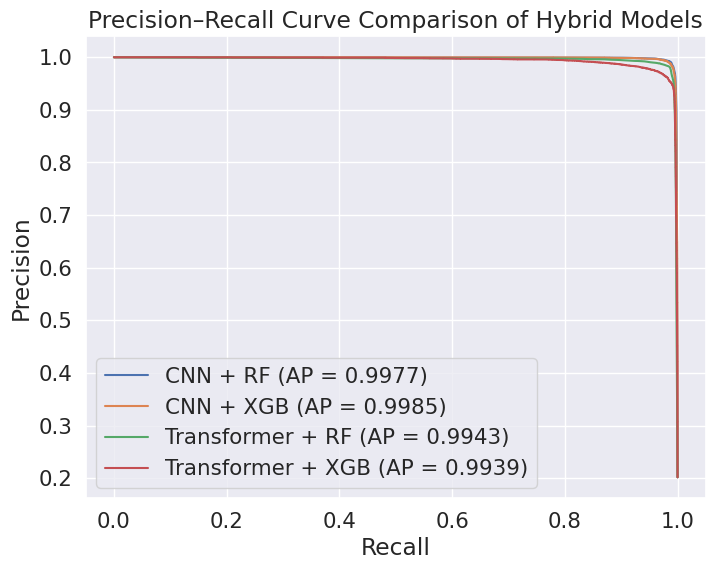

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Precision-Recall data
prec_cnn_rf, rec_cnn_rf, _ = precision_recall_curve(y_test, y_prob_rf)
prec_cnn_xgb, rec_cnn_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)

prec_trans_rf, rec_trans_rf, _ = precision_recall_curve(y_test, y_prob_rf_t)
prec_trans_xgb, rec_trans_xgb, _ = precision_recall_curve(y_test, y_prob_xgb_t)

# Average Precision (AP)
ap_cnn_rf = average_precision_score(y_test, y_prob_rf)
ap_cnn_xgb = average_precision_score(y_test, y_prob_xgb)
ap_trans_rf = average_precision_score(y_test, y_prob_rf_t)
ap_trans_xgb = average_precision_score(y_test, y_prob_xgb_t)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(rec_cnn_rf, prec_cnn_rf, label=f"CNN + RF (AP = {ap_cnn_rf:.4f})")
plt.plot(rec_cnn_xgb, prec_cnn_xgb, label=f"CNN + XGB (AP = {ap_cnn_xgb:.4f})")
plt.plot(rec_trans_rf, prec_trans_rf, label=f"Transformer + RF (AP = {ap_trans_rf:.4f})")
plt.plot(rec_trans_xgb, prec_trans_xgb, label=f"Transformer + XGB (AP = {ap_trans_xgb:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison of Hybrid Models")
plt.legend()
plt.grid(True)
plt.show()


Predict new link

In [ ]:
def preprocess_url(url, tokenizer, max_len):
    url = url.lower()
    seq = tokenizer.texts_to_sequences([url])
    padded = pad_sequences(seq, maxlen=max_len, padding='post')
    return padded


In [ ]:
def predict_url_cnn_rf(url):
    # preprocessing
    x = preprocess_url(url, tokenizer, MAX_LEN)

    # extract feature (CNN)
    feature = cnn_feature_extractor.predict(x)

    # classify (Random Forest)
    prob = rf_clf.predict_proba(feature)[0][1]
    label = "phishing" if prob >= 0.5 else "legitimate"

    return label, prob


In [ ]:
long_legit_urls = [
    "https://accounts.google.com/signin/v2/identifier?service=mail",
    "https://www.amazon.com/ap/signin?openid.return_to=https://www.amazon.com",
    "https://www.bca.co.id/id/Individu/layanan/E-Banking/Internet-Banking"
]

for url in long_legit_urls:
    label, prob = predict_url_cnn_rf(url)
    print(f"{url}")
    print(f"Prediction: {label} (prob={prob:.4f})")
    print("-"*60)


NameError: name 'tokenizer' is not defined